## This lecture is about INTRODUCTION TO MACHINE LEARNING (Part I)

**Previously:** Text processing (L2) · Parsing (L3) · Word representation (L4)

**Outline:**
- AI → ML → Deep Learning; ML categories (by purpose, functionality, learning paradigm, output)
- The ML model: learner, cost function, optimization
- **Supervised learning, regression:** linear regression, squared-error cost, gradient descent, learning rate, multiple linear regression, feature scaling, feature engineering, polynomial regression
- **Supervised learning, classification:** why not linear regression, odds and log-odds, sigmoid, **logistic regression**, log-loss, gradient descent
- **Overfitting:** bias vs variance, more data, feature selection, **regularization** (L1, L2, Elastic Net)
- **Unsupervised learning:** clustering, **K-Means**

### Final project (from the announcements)
- **40%** of the grade; in-class short presentation + weekly one-page updates + report + code; teams of 2–3.
- Topics: proposed by the instructor (Canvas), thesis-related, or student suggestion. Scope ≈ 2–3 days of work per person (e.g. one method implementation per student).
- **Submission:** everything zipped as `TeamNumber.zip` (e.g. `101.zip`).
  - **Report (PDF only)**, scientific-paper format: Title, Authors, Abstract, Introduction (motivation, problem, challenges, contribution bullets), Prior Work (with references), Methods (diagrams/flowcharts), Dataset (source, labels, size and split tables), Results (tables, several metrics), Discussion (findings, challenges, strengths/shortcomings, test-set examples), References, Appendix (user manual: environment setup and how to run).
  - **Code:** Python with classes and functions; a comment for each class/function (what it does, input, output); **unit tests** (`assert`); a separate **`demo.py`** (exact name) that runs on user-provided input *and* on pre-defined inputs.
  - **Dataset:** link if online; provide code to regenerate processed data/features, or submit them.
- **Timeline:** Oct 20 topic introduction · **Nov 3** teams and topic finalized · Nov 9 first one-page progress report (4 weekly submissions) · Dec 1 in-class presentation · **Dec 18** final submission.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

# AI, ML and categories
**Computer Science ⊃ AI ⊃ Machine Learning ⊃ Deep Learning**; NLP and Computer Vision are application areas that draw on ML / DL.

## By purpose
| | Focus | NLP use cases | Example methods |
|---|---|---|---|
| **Descriptive** | analyze and summarize historical data to reveal patterns ("what happened / what is happening") | topic modeling, summarization, sentiment analysis | clustering (K-Means, hierarchical), dimensionality reduction (PCA, t-SNE), association rule mining |
| **Predictive** | forecast future or unknown values from patterns in historical data ("what will happen") | text classification (spam, sentiment), intent recognition, next-word prediction / autocomplete | logistic regression, SVMs, Transformers; RNNs, LSTMs, BERT, GPT; seq2seq (MT, summarization) |
| **Prescriptive** | recommend actions or strategies that lead to desired outcomes ("what should we do") | conversational AI optimization, content recommendation, policy & decision support | reinforcement learning, multi-objective optimization, goal-constrained generation (fine-tuned GPT) |

## By functionality
| Generative | Discriminative |
|---|---|
| learns the **joint** distribution **P(X, Y)** | learns the **conditional** distribution **P(Y \| X)**, or a decision boundary directly |
| models how the data is generated → can **generate new samples** like the training data | separates classes (classification) or predicts a value (regression) |
| e.g. Naive Bayes, HMMs, GPT | e.g. logistic regression, SVMs, BERT classifiers |

## By learning paradigm
| Paradigm | Data | Idea |
|---|---|---|
| **Supervised** | labeled (input + expected output) | compare prediction with the expected output and learn from the error |
| **Unsupervised** | unlabeled | find structure (e.g. clusters) on its own |
| **Semi-supervised** | a few labels + many unlabeled | e.g. self-training: label confident unlabeled points and retrain |
| **Reinforcement** | rewards from an environment | an agent learns by trial and error (e.g. DeepMind's agent teaching itself parkour) |
| **Self-supervised** | unlabeled; labels come from the data itself | **pretext** training on unlabeled data (e.g. predict masked words) → **transfer** → **downstream** task training on labeled data |

## By output
- **Regression**: real/continuous output
- **Classification**: a category (discrete)
- **Clustering**: divide data into groups by similarity
- **Ranking**: order data points by some criterion
- **Generation**: generate new samples

## The ML model
**Input → Learner → Output**, compared with the **Actual output** using a **metric / cost function**. An **optimization strategy** uses that cost to adjust the learner's parameters.

# Supervised Learning: Regression
- **Objective:** estimate the value of the target variable for a new set of input features.
- **Approach:** learn the relationship between **independent variables** (features) and a **dependent variable** (target) from training data.
- **Output:** continuous values (temperature, price, weight, …).

## Linear regression
**Linear:** fit a straight line · **Regression:** predict a number.

Example: systolic blood pressure vs body-mass index (536 adolescents, r = 0.436).

| BMI (kg/m²) | Blood pressure (mmHg) |
|---|---|
| 19 | 120 |
| 22 | 126 |
| 26 | 125 |
| 29 | 131 |

**Terminology:** $x$ = input / feature · $y$ = output / target · $(x^{(i)}, y^{(i)})$ = the $i$-th **training example** · $m$ = number of training samples · $\hat{y}$ = prediction

**Training data → learning algorithm → $f$**, and then $x \to f \to \hat{y}$.

**Model:** $f_{w,b}(x) = wx + b$ ($w$ = slope, $b$ = intercept)

**Model parameters:** configuration variables internal to the model whose values are estimated from the data, here $w$ and $b$.

Find $w, b$ so that the predictions $\hat{y}^{(i)}$ are as close as possible to the actual $y^{(i)}$ for all samples.

## Cost function
**Definition:** a function that quantifies the error between the model's predictions and the actual values. **Purpose:** measure how well a model performs.

Error for one sample: $(\hat{y}^{(i)} - y^{(i)})^2$. **Squared-error cost function:**
$$J(w, b) = \frac{1}{2m}\sum_{i=1}^{m}\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)^2$$
(the ½ just cancels the 2 when we differentiate.)

**Fun fact: why square the error?**
1. Emphasizes larger errors
2. Differentiable
3. Convex (one minimum for linear regression)
4. Analytically simple (closed-form solution exists)
5. Statistical justification (maximum likelihood under Gaussian noise)

**Disadvantage:** makes the model **sensitive to outliers**.

**Goal:** $\min_{w,b} J(w, b)$

In [2]:
bmi = np.array([19, 22, 26, 29], dtype=float)
bp  = np.array([120, 126, 125, 131], dtype=float)

def predict(x, w, b):
    return w * x + b

def cost(x, y, w, b):
    m = len(x)
    return ((predict(x, w, b) - y) ** 2).sum() / (2 * m)

for w, b in [(0, 125), (1, 100), (1.0, 101.5)]:
    print(f'w={w:4}, b={b:6}  ->  J = {cost(bmi, bp, w, b):.3f}')

w=   0, b=   125  ->  J = 7.750
w=   1, b=   100  ->  J = 2.750
w= 1.0, b= 101.5  ->  J = 1.625


### Cost function intuition (simplified: $b = 0$, $f_w(x) = wx$)
Training data (1, 1), (2, 2), (3, 3). For each $w$ we get one value of $J(w)$; plotting them gives a **bowl** with its minimum at $w = 1$, where $J(w) = 0$ (a perfect fit).

**General form:** with both $w$ and $b$, $J(w, b)$ is a 3-D bowl (shown as a contour plot).

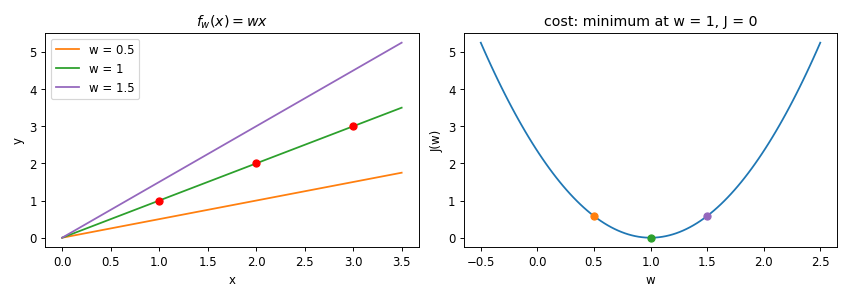

In [3]:
x = np.array([1, 2, 3.]); y = np.array([1, 2, 3.])
ws = np.linspace(-0.5, 2.5, 100)
J = [((w * x - y) ** 2).sum() / (2 * len(x)) for w in ws]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].scatter(x, y, c='red', zorder=3)
for w, c in [(0.5, 'tab:orange'), (1, 'tab:green'), (1.5, 'tab:purple')]:
    ax[0].plot([0, 3.5], [0, 3.5 * w], c=c, label=f'w = {w}')
ax[0].set(xlabel='x', ylabel='y', title='$f_w(x) = wx$'); ax[0].legend()
ax[1].plot(ws, J)
for w, c in [(0.5, 'tab:orange'), (1, 'tab:green'), (1.5, 'tab:purple')]:
    ax[1].scatter(w, ((w * x - y) ** 2).sum() / 6, c=c, zorder=3)
ax[1].set(xlabel='w', ylabel='J(w)', title='cost: minimum at w = 1, J = 0')
plt.tight_layout(); plt.show()

### Jacobian
**Definition:** the matrix of all first-order partial derivatives of a vector-valued function of several variables. It captures how changes in the inputs change the outputs.

For $\mathbf{f}: \mathbb{R}^u \to \mathbb{R}^v$:
$$\mathbf{J} = \frac{d\mathbf{f}(\mathbf{x})}{d\mathbf{x}} = \left[\frac{\partial \mathbf{f}}{\partial x_1} \cdots \frac{\partial \mathbf{f}}{\partial x_u}\right] = \begin{bmatrix} \frac{\partial f_1}{\partial x_1} & \cdots & \frac{\partial f_1}{\partial x_u} \\ \vdots & \ddots & \vdots \\ \frac{\partial f_v}{\partial x_1} & \cdots & \frac{\partial f_v}{\partial x_u}\end{bmatrix}$$
For a scalar cost ($v = 1$), the Jacobian is just the **gradient** $\nabla J = [\partial J/\partial w, \partial J/\partial b]$, which is what gradient descent uses.

# Gradient Descent
**Strategy:**
1. Start with some $w, b$ (e.g. 0, 0).
2. Change $w, b$ to reduce $J(w, b)$.
3. Repeat (2) until reaching a minimum.

([Interactive demo](https://blog.skz.dev/gradient-descent))

If $J$ is **not convex**, there may be several minima and gradient descent can get stuck in a **local minimum**, depending on where it starts. (The squared-error cost of linear regression is convex, so it has a single global minimum.)

**At each point, two questions:** which **direction**? (the negative gradient, steepest descent) and what **step size**? (the learning rate times the gradient)

## Formula
$$w = w - \alpha \frac{\partial}{\partial w}J(w, b) \qquad b = b - \alpha \frac{\partial}{\partial b}J(w, b)$$
- $=$ means **assignment** here; $\alpha$ is the **learning rate**.
- **Simultaneously** update $w$ and $b$:

| ✅ CORRECT | ❌ INCORRECT |
|---|---|
| `w_tmp = w - α ∂J/∂w (w, b)` | `w_tmp = w - α ∂J/∂w (w, b)` |
| `b_tmp = b - α ∂J/∂b (w, b)` | `w = w_tmp` ← updated too early |
| `w = w_tmp` | `b_tmp = b - α ∂J/∂b (w, b)` ← uses the **new** w |
| `b = b_tmp` | `b = b_tmp` |

**Intuition:** where the slope $\partial J/\partial w$ is **positive**, $w$ decreases; where it's **negative**, $w$ increases. Either way it moves toward the minimum. Steps automatically get smaller near the minimum because the slope gets smaller, even with a fixed $\alpha$.

**Naming:** *gradient* = the derivative direction; *descent* = moving downhill. Using all $m$ samples at each step is **batch** gradient descent.

## Learning rate
- $\alpha$ **too small** → very slow, many tiny steps.
- $\alpha$ **too large** → overshoots the minimum, may oscillate or **diverge**.

## Gradient descent for linear regression
Repeat until convergence, simultaneously updating $w, b$:
$$w = w - \alpha\frac{1}{m}\sum_{i=1}^{m}\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)x^{(i)} \qquad b = b - \alpha\frac{1}{m}\sum_{i=1}^{m}\big(f_{w,b}(x^{(i)}) - y^{(i)}\big)$$

In [4]:
def gradients(x, y, w, b):
    err = predict(x, w, b) - y
    return (err * x).mean(), err.mean()          # dJ/dw, dJ/db

def gradient_descent(x, y, w=0., b=0., alpha=0.01, iters=1000, simultaneous=True):
    history = []
    for _ in range(iters):
        if simultaneous:
            dw, db = gradients(x, y, w, b)
            w, b = w - alpha * dw, b - alpha * db     # both use the OLD w, b
        else:
            dw, _ = gradients(x, y, w, b); w = w - alpha * dw
            _, db = gradients(x, y, w, b); b = b - alpha * db   # uses the NEW w (incorrect)
        history.append(cost(x, y, w, b))
    return w, b, history

# Toy data first: should find w = 1, b = 0
w, b, _ = gradient_descent(x, y, alpha=0.1, iters=2000)
print(f'toy data      : w = {w:.4f}, b = {b:.4f}')

# BMI -> blood pressure (center x so plain GD converges quickly; see feature scaling below)
xc = bmi - bmi.mean()
w, b, hist = gradient_descent(xc, bp, alpha=0.05, iters=2000)
print(f'BMI (centered): w = {w:.4f}, b = {b:.4f}  ->  BP = {w:.3f} * (BMI - {bmi.mean()}) + {b:.2f}')
print(f'                in original units: BP = {w:.3f} * BMI + {b - w * bmi.mean():.2f}')
print('closed-form check (np.polyfit):', np.polyfit(bmi, bp, 1))
print(f'predicted BP for BMI = 32: {w * (32 - bmi.mean()) + b:.1f} mmHg')

toy data      : w = 1.0000, b = 0.0000
BMI (centered): w = 0.9138, b = 125.5000  ->  BP = 0.914 * (BMI - 24.0) + 125.50
                in original units: BP = 0.914 * BMI + 103.57
closed-form check (np.polyfit): [  0.9138 103.569 ]
predicted BP for BMI = 32: 132.8 mmHg


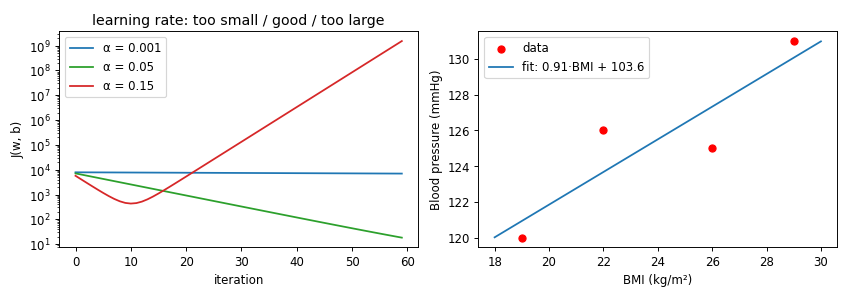

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for alpha, c in [(0.001, 'tab:blue'), (0.05, 'tab:green'), (0.15, 'tab:red')]:
    _, _, h = gradient_descent(xc, bp, alpha=alpha, iters=60)
    ax[0].plot(h, c=c, label=f'α = {alpha}')
ax[0].set(yscale='log', xlabel='iteration', ylabel='J(w, b)', title='learning rate: too small / good / too large')
ax[0].legend()

xs = np.linspace(18, 30, 10)
ax[1].scatter(bmi, bp, c='red', zorder=3, label='data')
ax[1].plot(xs, w * (xs - bmi.mean()) + b, label=f'fit: {w:.2f}·BMI + {b - w * bmi.mean():.1f}')
ax[1].set(xlabel='BMI (kg/m²)', ylabel='Blood pressure (mmHg)'); ax[1].legend()
plt.tight_layout(); plt.show()

In [6]:
# Simultaneous vs incorrect (sequential) update on the toy data, starting from w = b = 0
for simul in (True, False):
    w_, b_, h_ = gradient_descent(x, y, alpha=0.1, iters=3, simultaneous=simul)
    print(f"{'correct  ' if simul else 'incorrect'}: after 3 steps w = {w_:.4f}, b = {b_:.4f}, J = {h_[-1]:.4f}")
print('Different numbers: the incorrect version computes db with the already-updated w,')
print('so it is no longer following the gradient of J at the current point.')

correct  : after 3 steps w = 0.7696, b = 0.3229, J = 0.0272
incorrect: after 3 steps w = 0.8055, b = 0.1803, J = 0.0344
Different numbers: the incorrect version computes db with the already-updated w,
so it is no longer following the gradient of J at the current point.


# Multiple Linear Regression (general form)
More than one feature (e.g. BMI, age, sodium intake → blood pressure):
- $x_j$: the $j$-th feature · $n$: number of features · $x_j^{(i)}$: value of feature $j$ in training sample $i$

$$f_{\vec{w},b}(\vec{x}) = w_1x_1 + w_2x_2 + \dots + w_nx_n + b$$

**Vector form:** $\vec{w} = [w_1, \dots, w_n]$, $\vec{x} = [x_1, \dots, x_n]$, so $f_{\vec{w},b}(\vec{x}) = \vec{w}\cdot\vec{x} + b$ (a dot product; in NumPy, `X @ w + b`, which is much faster than a loop).

**Gradient descent** ($n \ge 2$), simultaneously for $j = 1..n$ and $b$:
$$w_j = w_j - \alpha\frac{1}{m}\sum_{i=1}^{m}\big(f_{\vec{w},b}(\vec{x}^{(i)}) - y^{(i)}\big)x_j^{(i)} \qquad b = b - \alpha\frac{1}{m}\sum_{i=1}^{m}\big(f_{\vec{w},b}(\vec{x}^{(i)}) - y^{(i)}\big)$$

In [7]:
def gd_multi(X, y, alpha=0.1, iters=1000):
    m, n = X.shape
    w, b, hist = np.zeros(n), 0.0, []
    for _ in range(iters):
        err = X @ w + b - y                    # vectorized predictions for all samples
        w, b = w - alpha * (X.T @ err) / m, b - alpha * err.mean()
        hist.append((err ** 2).mean() / 2)
    return w, b, hist

rng = np.random.default_rng(0)
m = 200
X = np.column_stack([rng.uniform(17, 35, m),       # BMI
                     rng.uniform(12, 18, m),       # age
                     rng.uniform(1000, 5000, m)])  # sodium (mg/day)
true_w, true_b = np.array([1.2, 0.8, 0.004]), 75
y_multi = X @ true_w + true_b + rng.normal(0, 3, m)
print('feature ranges:', X.min(0).round(1), 'to', X.max(0).round(1))

feature ranges: [  17.    12.  1019.6] to [  34.9   18.  4998. ]


# Feature Scaling
When features have very different ranges (e.g. $500 < x_1 < 1000$ and $0.01 < x_2 < 10$), the cost surface becomes a long, thin ellipse: gradient descent **zig-zags** and needs a tiny $\alpha$.

Feature scaling normalizes the ranges so that **no feature dominates the gradient updates**. The cost surface becomes more symmetric, so gradient descent can take larger, more efficient steps toward the minimum.

## Methods
| Method | Formula | Range |
|---|---|---|
| **Divide by max** | $x / x_{max}$ | $0 \le x' \le 1$ (e.g. $500<x_1<1000 \to 0.5<x_1'<1$; $0.01<x_2<10 \to 0.001<x_2'<1$) |
| **Mean normalization** | $\dfrac{x - \mu_x}{x_{max} - x_{min}}$ | $-1 \le x' \le 1$ |
| **Z-score normalization** | $\dfrac{x - \mu_x}{\sigma_x}$ | mean 0, std 1 (mostly within ±3) |

$\mu_x$: mean, $\sigma_x$: standard deviation. ⚠ Compute $\mu, \sigma$ on the **training** set and reuse them for new data.

divide by max        min [0.49 0.67 0.2 ]  max [1. 1. 1.]
mean normalization   min [-0.54 -0.52 -0.51]  max [0.46 0.48 0.49]
z-score              min [-1.78 -1.81 -1.9 ]  max [1.52 1.65 1.81]
learned w: [1.229  0.7251 0.0039]  b: 75.62    (true w: [1.2   0.8   0.004]  b: 75 )


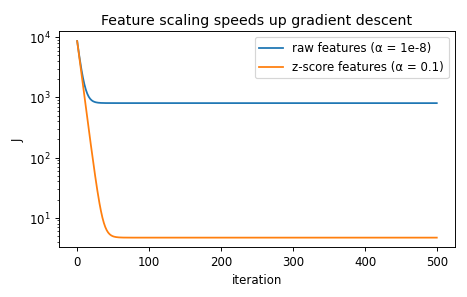

In [8]:
def divide_by_max(X): return X / X.max(0)
def mean_norm(X):     return (X - X.mean(0)) / (X.max(0) - X.min(0))
def zscore(X):        return (X - X.mean(0)) / X.std(0)

for name, fn in [('divide by max', divide_by_max), ('mean normalization', mean_norm), ('z-score', zscore)]:
    Xs = fn(X)
    print(f'{name:20} min {Xs.min(0).round(2)}  max {Xs.max(0).round(2)}')

# Gradient descent without vs with scaling
_, _, h_raw = gd_multi(X, y_multi, alpha=1e-8, iters=500)     # anything bigger diverges on raw sodium values
w_s, b_s, h_z = gd_multi(zscore(X), y_multi, alpha=0.1, iters=500)

plt.figure(figsize=(5.5, 3.5))
plt.plot(h_raw, label='raw features (α = 1e-8)'); plt.plot(h_z, label='z-score features (α = 0.1)')
plt.yscale('log'); plt.xlabel('iteration'); plt.ylabel('J'); plt.legend(); plt.title('Feature scaling speeds up gradient descent')
plt.tight_layout(); plt.show()

# convert weights back to original units
w_orig = w_s / X.std(0); b_orig = b_s - (w_s * X.mean(0) / X.std(0)).sum()
print('learned w:', w_orig.round(4), ' b:', round(b_orig, 2), '   (true w:', true_w, ' b:', true_b, ')')

# Feature Engineering
**Definition:** using intuition (and domain knowledge) to create new features from the original ones by **selecting**, **combining**, or **transforming** them.
e.g. from *height* and *weight* create **BMI** = weight / height²; from *frontage* and *depth* create *area*.

**Goals:**
- **Improve accuracy**: better capture the relationships in the data.
- **Reduce complexity**: lower dimensionality, easier to learn, less overfitting.
- **Handle data issues**: missing values, outliers, categorical data.
- **Integrate domain knowledge**: features that encode specific insights about the problem.

# Polynomial Regression
- Captures **non-linear** relationships between features and target.
- Modeled as an $n$-th degree polynomial: $f(x) = w_1x + w_2x^2 + \dots + w_nx^n + b$, which is still *linear in the parameters*, so it's just linear regression on engineered features $x, x^2, …$ (scale them!).

| Advantages | Disadvantages |
|---|---|
| captures complex non-linear relationships | **prone to overfitting**, especially with high degrees |
| coefficients are easy to interpret | computationally expensive for large datasets |
| flexible, adapts to different data types | susceptible to noise |
| | less interpretable than simple linear regression |

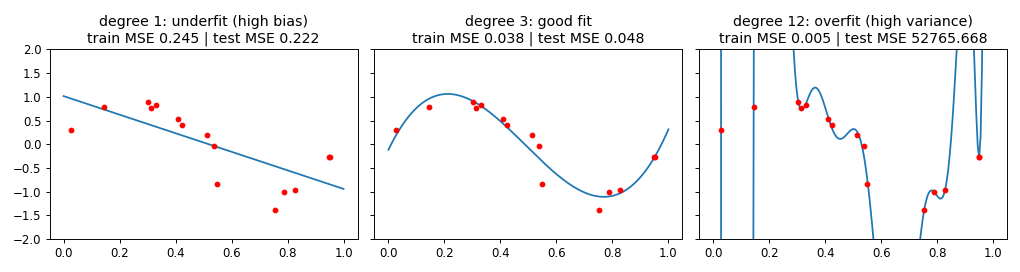

In [9]:
rng = np.random.default_rng(1)
xp = np.sort(rng.uniform(0, 1, 15))
yp = np.sin(2 * np.pi * xp) + rng.normal(0, 0.2, len(xp))
x_test = np.sort(rng.uniform(0, 1, 100)); y_test = np.sin(2 * np.pi * x_test) + rng.normal(0, 0.2, 100)

def poly_features(x, degree):
    return np.column_stack([x ** d for d in range(1, degree + 1)])

xx = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, deg, title in zip(axes, [1, 3, 12], ['degree 1: underfit (high bias)', 'degree 3: good fit', 'degree 12: overfit (high variance)']):
    coef = np.polyfit(xp, yp, deg)
    tr = np.mean((np.polyval(coef, xp) - yp) ** 2); te = np.mean((np.polyval(coef, x_test) - y_test) ** 2)
    ax.scatter(xp, yp, c='red', s=15, zorder=3); ax.plot(xx, np.polyval(coef, xx))
    ax.set(ylim=(-2, 2), title=f'{title}\ntrain MSE {tr:.3f} | test MSE {te:.3f}')
plt.tight_layout(); plt.show()

# Supervised Learning: Classification
- Categorize data points into **discrete classes**.
- Learn the characteristics of each class from labeled training data.
- **Output:** discrete labels (spam / not spam, dog / cat, healthy / sick). **Binary** classification: $y \in \{0, 1\}$ (negative / positive class).
- **Objective:** assign a data point to one of the predefined classes based on its features.

## Why not linear regression?
Example: tumor size (diameter in cm) → malignant? (yes = 1 / no = 0).
Fit $y = wx + b$ and use a **threshold** (0.5): predict malignant if $f(x) \ge 0.5$. The **decision boundary** is where $f(x) = 0.5$.

**Problem:** add one very large (clearly malignant) tumor. The line tilts, the threshold point moves right, and some malignant tumors are now classified as benign. Also, $f(x)$ can be < 0 or > 1, which makes no sense as a probability.

linear regression + threshold            boundary = 3.00 cm; misclassified malignant: 0
add one big tumor → boundary shifts      boundary = 3.69 cm; misclassified malignant: 1


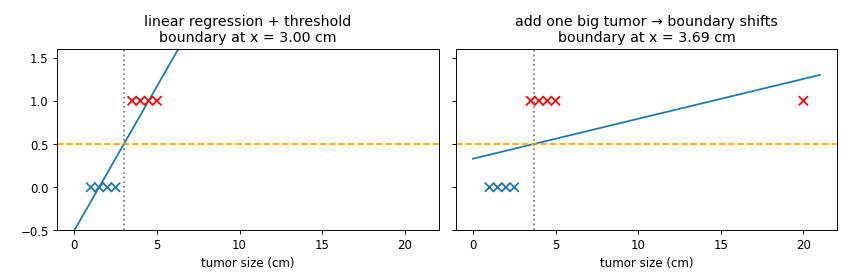

In [10]:
tumor = np.array([1, 1.5, 2, 2.5, 3.5, 4, 4.5, 5.])
label = np.array([0, 0, 0, 0, 1, 1, 1, 1.])

def boundary_from_linreg(x, y):
    w, b = np.polyfit(x, y, 1)
    return (0.5 - b) / w, (w, b)          # x where w*x + b = 0.5

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3), sharey=True)
for a, (xs_, ys_, t) in zip(ax, [(tumor, label, 'linear regression + threshold'),
                                 (np.append(tumor, 20), np.append(label, 1), 'add one big tumor → boundary shifts')]):
    xb, (w, b) = boundary_from_linreg(xs_, ys_)
    a.scatter(xs_, ys_, c=['tab:blue' if v == 0 else 'red' for v in ys_], marker='x', s=60, zorder=3)
    xt_line = np.linspace(0, 21, 50); a.plot(xt_line, w * xt_line + b); a.axhline(0.5, c='orange', ls='--')
    a.axvline(xb, c='gray', ls=':'); a.set(title=f'{t}\nboundary at x = {xb:.2f} cm', xlabel='tumor size (cm)', ylim=(-0.5, 1.6))
    print(f'{t:40} boundary = {xb:.2f} cm; misclassified malignant: {int(((w * xs_ + b) < 0.5)[ys_ == 1].sum())}')
plt.tight_layout(); plt.show()

## Classification as the probability of an event
We want $P(y = 1)$, but a probability lives in $[0, 1]$, which is awkward for a linear function (range $(-\infty, \infty)$).

**Step 1: odds** (escape the upper bound): $\text{odds} = \dfrac{P(y=1)}{P(y=0)} = \dfrac{P}{1-P} \in [0, \infty)$
- P = 0.5 → odds = 1 (equally likely); P = 0.9 → odds = 9 (9× more likely to be class 1)

**Step 2: log-odds (logit)** (escape the lower bound): $\log\dfrac{P}{1-P} \in (-\infty, \infty)$, the same range as a linear function.
- P = 0.5 → log-odds = 0; P = 0.9 → log-odds ≈ 2.2

**Step 3:** assume the log-odds is **linear** in the features, and solve for $P$:
$$\log\frac{P}{1-P} = \vec{w}\cdot\vec{x} + b \;\Rightarrow\; \frac{P}{1-P} = e^{\vec{w}\cdot\vec{x}+b} \;\Rightarrow\; P = \frac{1}{1 + e^{-(\vec{w}\cdot\vec{x}+b)}}$$

## Sigmoid function
$$g(z) = \frac{1}{1 + e^{-z}}, \quad 0 < g(z) < 1$$
$g(0) = 0.5$; large positive $z$ → 1; large negative $z$ → 0.

P =  0.1  odds =   0.11  log-odds =  -2.20
P =  0.5  odds =   1.00  log-odds =   0.00
P = 0.75  odds =   3.00  log-odds =   1.10
P =  0.9  odds =   9.00  log-odds =   2.20
P = 0.99  odds =  99.00  log-odds =   4.60


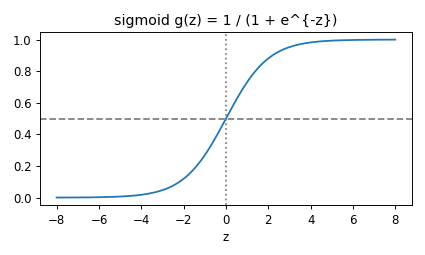

In [11]:
for P in [0.1, 0.5, 0.75, 0.9, 0.99]:
    odds = P / (1 - P)
    print(f'P = {P:4}  odds = {odds:6.2f}  log-odds = {np.log(odds):6.2f}')

sigmoid = lambda z: 1 / (1 + np.exp(-z))
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(5, 3)); plt.plot(z, sigmoid(z)); plt.axhline(0.5, ls='--', c='gray'); plt.axvline(0, ls=':', c='gray')
plt.title('sigmoid g(z) = 1 / (1 + e^{-z})'); plt.xlabel('z'); plt.tight_layout(); plt.show()

# Logistic Regression
**Definition:** a classification model that predicts the **probability** of the positive class by passing a linear function through the sigmoid.

**Formulation:**
$$z = \vec{w}\cdot\vec{x} + b, \qquad f_{\vec{w},b}(\vec{x}) = g(z) = \frac{1}{1 + e^{-(\vec{w}\cdot\vec{x}+b)}} = P(y = 1 \mid \vec{x}; \vec{w}, b)$$
Predict $\hat{y} = 1$ if $f \ge 0.5$, i.e. if $z \ge 0$, so the **decision boundary** is $\vec{w}\cdot\vec{x} + b = 0$ (a line/plane; non-linear if you use polynomial features).

## Cost function
Squared error with the sigmoid gives a **non-convex** $J$ (many local minima), so we use the **log loss**:
$$L\big(f_{\vec{w},b}(\vec{x}^{(i)}), y^{(i)}\big) = \begin{cases} -\log\big(f_{\vec{w},b}(\vec{x}^{(i)})\big) & \text{if } y^{(i)} = 1 \\ -\log\big(1 - f_{\vec{w},b}(\vec{x}^{(i)})\big) & \text{if } y^{(i)} = 0 \end{cases}$$
- $y = 1$: loss → 0 as $f$ → 1, and → ∞ as $f$ → 0 (confidently wrong is punished hard).
- $y = 0$: loss → 0 as $f$ → 0, and → ∞ as $f$ → 1.

$$J(\vec{w}, b) = \frac{1}{m}\sum_{i=1}^{m} L\big(f_{\vec{w},b}(\vec{x}^{(i)}), y^{(i)}\big)$$

**Simplified (one line, since $y$ is 0 or 1):**
$$L = -y^{(i)}\log\big(f(\vec{x}^{(i)})\big) - (1 - y^{(i)})\log\big(1 - f(\vec{x}^{(i)})\big)$$
This is **binary cross-entropy**; it comes from maximum likelihood and is **convex**.

## Gradient descent
Repeat until convergence, simultaneously for all $w_j$ and $b$:
$$w_j = w_j - \alpha\frac{1}{m}\sum_{i=1}^{m}\big(f_{\vec{w},b}(\vec{x}^{(i)}) - y^{(i)}\big)x_j^{(i)} \qquad b = b - \alpha\frac{1}{m}\sum_{i=1}^{m}\big(f_{\vec{w},b}(\vec{x}^{(i)}) - y^{(i)}\big)$$
It **looks identical** to linear regression, but $f$ is now the sigmoid of $\vec{w}\cdot\vec{x} + b$ instead of $\vec{w}\cdot\vec{x} + b$.

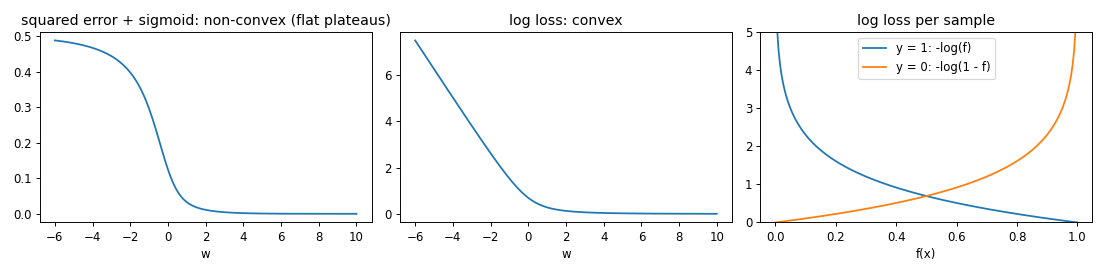

In [12]:
# Convex vs non-convex: cost as a function of w (b fixed) on the tumor data
def lr_costs(w, b=-3.0):
    p = sigmoid(w * (tumor + b))            # boundary kept at 3 cm, slope w varies
    mse = ((p - label) ** 2).mean() / 2
    logloss = -(label * np.log(p + 1e-12) + (1 - label) * np.log(1 - p + 1e-12)).mean()
    return mse, logloss

ws = np.linspace(-6, 10, 300)
c = np.array([lr_costs(w) for w in ws])
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(ws, c[:, 0]); ax[0].set(title='squared error + sigmoid: non-convex (flat plateaus)', xlabel='w')
ax[1].plot(ws, c[:, 1]); ax[1].set(title='log loss: convex', xlabel='w')
f = np.linspace(0.001, 0.999, 200)
ax[2].plot(f, -np.log(f), label='y = 1: -log(f)'); ax[2].plot(f, -np.log(1 - f), label='y = 0: -log(1 - f)')
ax[2].set(ylim=(0, 5), xlabel='f(x)', title='log loss per sample'); ax[2].legend()
plt.tight_layout(); plt.show()

In [13]:
def logistic_regression_gd(X, y, alpha=0.1, iters=5000):
    m, n = X.shape
    w, b, hist = np.zeros(n), 0.0, []
    for _ in range(iters):
        f = sigmoid(X @ w + b)
        err = f - y
        w, b = w - alpha * (X.T @ err) / m, b - alpha * err.mean()      # same form as linear regression
        hist.append(-(y * np.log(f + 1e-12) + (1 - y) * np.log(1 - f + 1e-12)).mean())
    return w, b, hist

# 1 feature: tumor size (incl. the large tumor that broke linear regression)
Xt = np.append(tumor, 20).reshape(-1, 1); yt = np.append(label, 1)
w, b, hist = logistic_regression_gd(Xt, yt, alpha=0.5, iters=5000)
print(f'w = {w[0]:.3f}, b = {b:.3f}, decision boundary x = {-b / w[0]:.2f} cm, final log loss = {hist[-1]:.4f}')
for size in [2, 3.5, 4, 5]:
    print(f'  P(malignant | {size} cm) = {sigmoid(w[0] * size + b):.3f}')

w = 5.845, b = -17.366, decision boundary x = 2.97 cm, final log loss = 0.0125
  P(malignant | 2 cm) = 0.003
  P(malignant | 3.5 cm) = 0.957
  P(malignant | 4 cm) = 0.998
  P(malignant | 5 cm) = 1.000


w = [2.386 2.013] b = -13.817


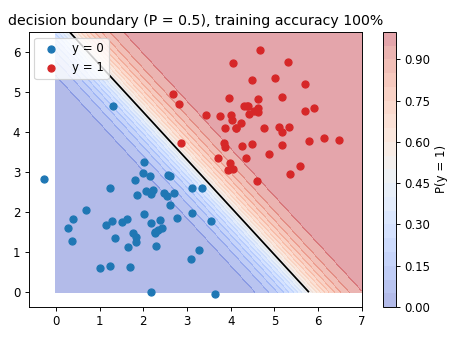

In [14]:
# 2 features: a linear decision boundary  w1*x1 + w2*x2 + b = 0
rng = np.random.default_rng(3)
X0 = rng.normal([2, 2], 0.8, (50, 2)); X1 = rng.normal([4.5, 4], 0.8, (50, 2))
X2 = np.vstack([X0, X1]); y2 = np.array([0] * 50 + [1] * 50)
w2, b2, _ = logistic_regression_gd(X2, y2, alpha=0.3, iters=3000)
acc = ((sigmoid(X2 @ w2 + b2) >= 0.5) == y2).mean()

g1, g2 = np.meshgrid(np.linspace(0, 7, 200), np.linspace(0, 6.5, 200))
P = sigmoid(np.c_[g1.ravel(), g2.ravel()] @ w2 + b2).reshape(g1.shape)
plt.figure(figsize=(5.5, 4))
plt.contourf(g1, g2, P, levels=20, cmap='coolwarm', alpha=0.4); plt.colorbar(label='P(y = 1)')
plt.contour(g1, g2, P, levels=[0.5], colors='k')
plt.scatter(*X0.T, c='tab:blue', label='y = 0'); plt.scatter(*X1.T, c='tab:red', label='y = 1')
plt.title(f'decision boundary (P = 0.5), training accuracy {acc:.0%}'); plt.legend(); plt.tight_layout(); plt.show()
print('w =', w2.round(3), 'b =', round(b2, 3))

### NLP tie-in: logistic regression on TF-IDF features (from L4)
A classic baseline for text classification: represent each document with TF-IDF, then train logistic regression.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

train_texts = ["great movie, loved it", "what a wonderful film", "excellent acting and story",
               "terrible movie, hated it", "boring and awful film", "worst story ever"]
train_y = [1, 1, 1, 0, 0, 0]

vec = TfidfVectorizer()
clf = LogisticRegression().fit(vec.fit_transform(train_texts), train_y)

for t in ["loved the acting", "awful, boring story", "a wonderful story"]:
    p = clf.predict_proba(vec.transform([t]))[0, 1]
    print(f'{t:22} P(positive) = {p:.2f}')

top = np.argsort(clf.coef_[0])
names = vec.get_feature_names_out()
print('most negative words:', list(names[top[:4]]), '| most positive words:', list(names[top[-4:]]))

loved the acting       P(positive) = 0.58
awful, boring story    P(positive) = 0.43
a wonderful story      P(positive) = 0.55
most negative words: ['ever', 'worst', 'awful', 'boring'] | most positive words: ['excellent', 'acting', 'what', 'wonderful']


# Overfitting
**Definition:** a model tailored so closely to the specifics of the training data that it performs poorly on new, unseen data.

| | Underfit | Just right | Overfit |
|---|---|---|---|
| a.k.a. | **high bias** | generalizes | **high variance** |
| training error | high | low | very low |
| test error | high | low | high |
| regression | straight line through curved data | smooth curve | wiggly curve through every point |
| classification | boundary too simple | reasonable boundary | boundary wraps around individual points |

## Addressing underfitting / overfitting
1. **Collect more training samples**: with more data the overfit model is forced to smooth out.
2. **Feature selection** (include / exclude): ALL features + insufficient data → overfit; selected features + some data → better. (Downside: you may discard useful information.)
3. **Regularization**: add a **penalty on model complexity** to encourage simpler models that generalize better:
$$J(\vec{w}, b) = \frac{1}{2m}\sum_{i=1}^{m}\big(f_{\vec{w},b}(\vec{x}^{(i)}) - y^{(i)}\big)^2 + \text{Penalty}(\vec{w}, b)$$
$$\min_{\vec{w},b} J(\vec{w}, b) = \min_{\vec{w},b}\Bigg[\underbrace{\frac{1}{2m}\sum_{i=1}^{m}\big(f_{\vec{w},b}(\vec{x}^{(i)}) - y^{(i)}\big)^2}_{\text{mean squared error}} + \underbrace{\frac{\lambda}{2m}\sum_{j=1}^{n} w_j^2 + \frac{\lambda}{2m}b^2}_{\text{regularization term}}\Bigg]$$
   - $\lambda$ (a hyper-parameter) balances fitting the data vs keeping weights small. $\lambda = 0$ → may overfit; $\lambda$ huge → all $w_j \approx 0$ → underfit (flat line). Penalizing $b$ is optional and usually skipped.
   - Gradient descent just gets an extra term: $w_j = w_j - \alpha\big[\frac{1}{m}\sum(f - y)x_j^{(i)} + \frac{\lambda}{m}w_j\big]$

### Types of regularization
| Type | Penalty | Effect |
|---|---|---|
| **L1 (Lasso)** | $\lambda\sum\|w_j\|$ (absolute values) | can drive some coefficients to **exactly zero** → built-in **feature selection** |
| **L2 (Ridge)** | $\lambda\sum w_j^2$ (squares) | discourages large weights, but usually **no** coefficient becomes exactly zero |
| **Elastic Net** | L1 + L2 | useful when several features are **correlated** with each other |

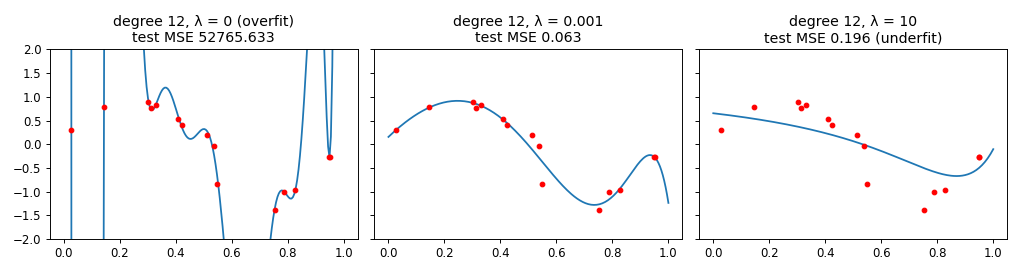

In [16]:
# Regularization fixes the degree-12 polynomial from before
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso, ElasticNet, LinearRegression
from sklearn.metrics import mean_squared_error

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for ax, lam in zip(axes, [0, 1e-3, 10]):
    model = make_pipeline(PolynomialFeatures(12, include_bias=False), StandardScaler(),
                          LinearRegression() if lam == 0 else Ridge(alpha=lam))
    model.fit(xp.reshape(-1, 1), yp)
    te = mean_squared_error(y_test, model.predict(x_test.reshape(-1, 1)))
    ax.scatter(xp, yp, c='red', s=15, zorder=3); ax.plot(xx, model.predict(xx.reshape(-1, 1)))
    ax.set(ylim=(-2, 2), title=f'degree 12, λ = {lam}\ntest MSE {te:.3f}')
axes[0].set_title(axes[0].get_title().replace('λ = 0', 'λ = 0 (overfit)'))
axes[2].set_title(axes[2].get_title() + ' (underfit)')
plt.tight_layout(); plt.show()

In [17]:
# L1 vs L2 vs Elastic Net: which coefficients become exactly zero?
rng = np.random.default_rng(5)
Xr = rng.normal(size=(100, 8))
Xr[:, 7] = Xr[:, 0] + rng.normal(0, 0.05, 100)           # feature 7 nearly duplicates feature 0 (correlated)
yr = 3 * Xr[:, 0] - 2 * Xr[:, 1] + 0.5 * Xr[:, 2] + rng.normal(0, 0.5, 100)   # only 3 features matter

for name, model in [('No regularization', LinearRegression()), ('L2 Ridge (α=10)', Ridge(alpha=10)),
                    ('L1 Lasso (α=0.1)', Lasso(alpha=0.1)), ('Elastic Net', ElasticNet(alpha=0.1, l1_ratio=0.5))]:
    coef = model.fit(Xr, yr).coef_
    print(f'{name:18} {np.round(coef, 2)}   zeros: {(np.abs(coef) < 1e-6).sum()}')

No regularization  [ 2.6  -1.97  0.48 -0.01  0.01 -0.13 -0.14  0.45]   zeros: 0
L2 Ridge (α=10)    [ 1.44 -1.79  0.38  0.02  0.03 -0.1  -0.11  1.43]   zeros: 0
L1 Lasso (α=0.1)   [ 2.24 -1.85  0.32  0.    0.   -0.   -0.    0.68]   zeros: 3
Elastic Net        [ 1.46 -1.81  0.35  0.    0.   -0.05 -0.06  1.43]   zeros: 2


# Unsupervised Learning
**Supervised:** input $x$ **with** labels $y$ → learn $x \to y$.
**Unsupervised:** input $x$ **only**, no labels → find structure in the data.

## Clustering
- **Definition:** an unsupervised technique that groups data points into subsets (**clusters**).
- **Goal:** points in the same cluster are more similar to each other than to points in other clusters.
- **Metric:** a similarity / distance measure on the features: **Euclidean**, **Manhattan**, or **cosine** similarity (common for text vectors).

**Clinical example: data-driven identification of hypertensive patient phenotypes**
- Class 1 (clusters 1 & 2): elderly females with high blood pressure and cardiovascular risk (ischemic heart disease, dyslipidemia)
- Class 2 (clusters 3 & 4): severe arterial hypertension (grades 2–3) with metabolic syndrome (carbohydrate metabolism disorders, lipid abnormalities)
- Class 3 (cluster 5): young males with family history, risk factors, subclinical organ damage
- Class 4 (clusters 6 & 7): grade 1 hypertension with advanced atherosclerosis

## K-Means
**Definition:** partition a dataset into a set number **K** of distinct, non-overlapping clusters.
**Goal:** similar items together, dissimilar items in different groups.

**Steps:**
1. Choose **K**.
2. Randomly initialize **K centroids**.
3. Calculate the distance between every point and each centroid.
4. **Assign** each point to its closest centroid's class.
5. Calculate the **mean** of each class.
6. **Move** each centroid to its class mean.
7. Repeat 3–6 until the centroids stop changing.

**Algorithm:**
1. Randomly initialize $K$ cluster centroids $\mu_1, \mu_2, \dots, \mu_K$
2. Repeat until no more change to the cluster centroids:
   - **Assign** points (for $i = 1..m$): $c^{(i)}$ = index of the closest centroid, $\min_k \|x^{(i)} - \mu_k\|^2$
   - **Update** centroids (for $k = 1..K$): $\mu_k$ = average of the points assigned to cluster $k$

**Notation:** $x^{(i)}$: data sample · $\mu_k$: centroid of cluster $k$ · $c^{(i)}$: index of the cluster $x^{(i)}$ is currently assigned to · $\mu_{c^{(i)}}$: centroid of the cluster $x^{(i)}$ is assigned to

**Cost (distortion) function:**
$$J\big(c^{(1)}, \dots, c^{(m)}, \mu_1, \dots, \mu_K\big) = \sum_{i=1}^{m}\big\|x^{(i)} - \mu_{c^{(i)}}\big\|^2$$
- The **assignment step** minimizes $J$ over the $c^{(i)}$ with the **$\mu$'s fixed**.
- The **update step** minimizes $J$ over the $\mu_k$ with the **$c$'s fixed**.
- So $J$ **never increases**; K-Means converges, though possibly to a local minimum, which is why it is usually run with several random initializations.

cost J per iteration (never increases): [1359.8  133.7  107.2]


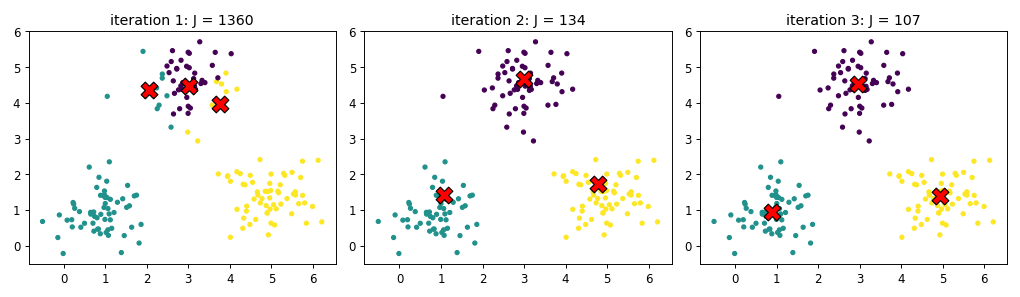

In [18]:
def kmeans(X, K, iters=20, seed=0, record=False):
    rng = np.random.default_rng(seed)
    mu = X[rng.choice(len(X), K, replace=False)]                 # 1) random init from data points
    snapshots, costs = [], []
    for _ in range(iters):
        d = ((X[:, None, :] - mu[None, :, :]) ** 2).sum(-1)      # squared distance to each centroid
        c = d.argmin(1)                                          # 2a) assign
        costs.append(d[np.arange(len(X)), c].sum())
        if record: snapshots.append((mu.copy(), c.copy()))
        new_mu = np.array([X[c == k].mean(0) if (c == k).any() else mu[k] for k in range(K)])   # 2b) update
        if np.allclose(new_mu, mu): break
        mu = new_mu
    return mu, c, costs, snapshots

rng = np.random.default_rng(7)
Xk = np.vstack([rng.normal(m_, 0.6, (60, 2)) for m_ in ([1, 1], [5, 1.5], [3, 4.5])])
mu, c, costs, snaps = kmeans(Xk, K=3, seed=4, record=True)
print('cost J per iteration (never increases):', np.round(costs, 1))

steps = [0, 1, len(snaps) - 1]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, s in zip(axes, steps):
    m_, c_ = snaps[s]
    ax.scatter(*Xk.T, c=c_, cmap='viridis', s=12)
    ax.scatter(*m_.T, c='red', marker='X', s=200, edgecolor='k')
    ax.set(title=f'iteration {s + 1}: J = {costs[s]:.0f}')
plt.tight_layout(); plt.show()

sklearn centroids:
 [[4.94 1.38]
 [0.89 0.94]
 [2.97 4.52]] 
inertia (= J): 107.2


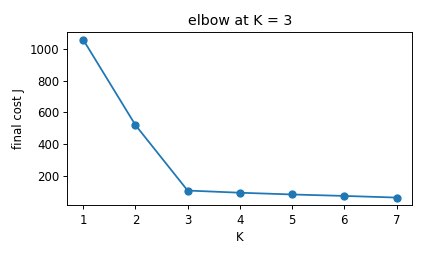

In [19]:
# Choosing K: the elbow method (cost vs K, best of several random inits)
Ks = range(1, 8)
best = [min(kmeans(Xk, K, seed=s)[2][-1] for s in range(5)) for K in Ks]
plt.figure(figsize=(5, 3)); plt.plot(list(Ks), best, 'o-'); plt.xlabel('K'); plt.ylabel('final cost J')
plt.title('elbow at K = 3'); plt.tight_layout(); plt.show()

# Same with scikit-learn
from sklearn.cluster import KMeans
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Xk)
print('sklearn centroids:\n', km.cluster_centers_.round(2), '\ninertia (= J):', round(km.inertia_, 1))

In [20]:
# NLP tie-in: cluster short documents by their TF-IDF vectors
docs = ["patient has high blood pressure", "hypertension and elevated blood pressure",
        "blood pressure medication increased", "the team won the football match",
        "great goal in the soccer game", "football season starts next week",
        "new phone has a better camera", "the laptop battery lasts longer", "phone and laptop prices drop"]
Xd = TfidfVectorizer(stop_words='english').fit_transform(docs)
labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Xd)
for k in range(3):
    print(f'cluster {k}:', [d for d, l in zip(docs, labels) if l == k])

cluster 0: ['the team won the football match', 'great goal in the soccer game', 'football season starts next week']
cluster 1: ['new phone has a better camera', 'the laptop battery lasts longer', 'phone and laptop prices drop']
cluster 2: ['patient has high blood pressure', 'hypertension and elevated blood pressure', 'blood pressure medication increased']


# Summary
| | Linear regression | Logistic regression | K-Means |
|---|---|---|---|
| Paradigm | supervised | supervised | unsupervised |
| Output | continuous value | probability → class | cluster index |
| Model | $\vec{w}\cdot\vec{x} + b$ | $g(\vec{w}\cdot\vec{x} + b)$ | K centroids $\mu_k$ |
| Cost | squared error | log loss (cross-entropy) | sum of squared distances to centroids |
| Optimization | gradient descent (or closed form) | gradient descent | alternate assign / update |
| Watch out for | feature scaling, outliers, overfitting | threshold choice, overfitting | choice of K, initialization, scaling |